# TimesNet one-class pretraining on the T = 32 benign windows of all 8 scenario folders

A **TimesNet** encoder (d = 128, d_ff = 64, D12) pretrained self-supervised (masked reconstruction + NT-Xent
contrastive + injected-violation heads P1–P3, D7) on the **benign** windows of `src/data/encoder_input/all/T32_benign/`
(80 / 10 / 10 split by sender vehicle over all 8 folders, fixed on disk), then scored one-class against the attack
windows of the test vehicles. Training code never opens a label file, but train / val hold benign windows only,
selected with attack labels when the input was built: a one-class setting, not label-free pretraining (user's choice,
2026-11-15; `src/model/all_t32_benign/README.md`).

This notebook only **reads**: the run folder written by `src.model.all_t32_benign.timesnet.train` (config, env,
history, feature history, steps, summary, `best.pt`) and the evaluation folder written by
`src.model.all_t32_benign.timesnet.evaluate` (score files saved **before** any label was read, then summary.json).
It never trains, never writes into a run folder and never opens a label file itself. Missing files or keys (a smoke
run, no evaluation yet) are reported and skipped. Loading / plotting helpers: `timesnet/plots.py`.

Sections: 1 input, 2 model, 3 training record, 4 reconstruction on val, 5 test (scores first, labels after),
6 context (not a fair comparison), 7 analysis.

Parameters. `RUN = None` picks the newest run folder under `src/runs/pretraining/all/T32_benign/` that has a
`history.jsonl`; `EVAL = None` picks that run's evaluation folder under `src/runs/evaluation/all/T32_benign/` (a full
evaluation `<run_id>` before a smoke one `<run_id>-smoke-<time>`); `RANDOM_EVAL = None` does the same for the
untrained control (`<run_id>-random-init`). Each can be set to a folder name or a path.

In [1]:
RUN = None  # e.g. "model-t32b-seed0"
EVAL = None  # e.g. "model-t32b-seed0"
RANDOM_EVAL = None  # e.g. "model-t32b-seed0-random-init"

Setup: repo-root check (RULE 5), imports, the run and evaluation folders, and a loud warning when either is a
smoke / short run (plumbing only, never a result).

In [2]:
import json
from pathlib import Path

assert (
    Path("src/model/all_t32_benign/timesnet/plots.py").is_file() and Path("CLAUDE.md").is_file()
), "run this notebook from the repo root"

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.model.all_t32_benign.timesnet import plots
from src.model.all_t32_benign.timesnet.base_config import PretrainConfig
from src.model.all_t32_benign.timesnet.config import T32BenignConfig
from src.model.all_t32_benign.timesnet.data import PretrainFirewall, load_split
from src.model.all_t32_benign.timesnet.heads import PretrainingModel

EXPECTED_ENCODER_PARAMS = 2_301_312  # D12: d = 128, d_ff = 64 (architecture fact, not a result)
EXPECTED_TOTAL_PARAMS = 2_402_461  # encoder + recon / P1-P3 / projection heads + the 13-number mask token

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)


def show(fig):
    # Displays a figure returned by plots.py; None means the helper printed why it skipped.
    if fig is not None:
        plt.show()


defaults = T32BenignConfig()
run = plots.RunFolder.pick(RUN)
ev = plots.EvalFolder.find(run.run_id, EVAL)
ev_random = plots.EvalFolder.find(run.run_id, RANDOM_EVAL, random_init=True)
DATA_DIR = Path(run.config.get("data_dir", defaults.data_dir))
CACHE_DIR = Path(run.config.get("cache_dir", defaults.cache_dir))
META = json.loads((DATA_DIR / "metadata.json").read_text())
FEATURES = META["features"]
print("run folder:       ", run.path)
print("evaluation folder:", ev.path if ev else "none yet (section 5 is skipped)")
print("random-init eval: ", ev_random.path if ev_random else "none")
print("data / cache:     ", DATA_DIR, "/", CACHE_DIR)
if run.is_short():
    print("\n*** SHORT / SMOKE RUN: plumbing check of the notebook; the numbers below are not results ***")
if ev is not None and ev.smoke:
    print("*** SMOKE EVALUATION: a few windows per split; every test number below is plumbing only, not a result ***")

run folder:        src/runs/pretraining/all/T32_benign/model-t32b-seed0
evaluation folder: src/runs/evaluation/all/T32_benign/model-t32b-seed0
random-init eval:  src/runs/evaluation/all/T32_benign/model-t32b-seed0-random-init
data / cache:      src/data/encoder_input/all/T32_benign / src/data/cache/all/T32_benign


## 1. Input

Seven splits on disk. Train / val / test hold the **benign** windows of disjoint sender-vehicle sets (80 / 10 / 10 by
vehicle key `<group>:<vehicle>`, stratified by group and vehicle class, seed 0); the four `test_<attack>` splits hold
the attack windows of the **test** vehicles. Counts come from `metadata.json`, next to the window count of each
numpy cache manifest (the cache holds features only). Only train and val are opened before section 5.

In [3]:
order = ["train", "val", "test", *plots.ATTACKS]
cbs = pd.DataFrame(META["counts_by_split"]).T.loc[order]
cbs = cbs[["windows", "messages", "links", "vehicles", "padding_share", "windows_1_3", "share_1_3"]]
for c in ("windows", "messages", "links", "vehicles", "windows_1_3"):
    cbs[c] = cbs[c].astype(int)
manifest = {}
for split in order:
    path = CACHE_DIR / split / "manifest.json"
    manifest[split] = json.loads(path.read_text())["n_windows"] if path.is_file() else None
cbs["cache windows"] = pd.Series(manifest)
cbs.columns = [
    "windows",
    "messages",
    "links (tracks)",
    "sender vehicles",
    "padding share",
    "1-3-row windows",
    "1-3-row share",
    "cache windows",
]
assert all(m is None or m == w for m, w in zip(cbs["cache windows"], cbs["windows"])), "cache differs from metadata"
cbs

,windows,messages,links (tracks),sender vehicles,padding share,1-3-row windows,1-3-row share,cache windows
train,502773,8365846,401986,4206,0.4800,68836,0.1369,502773
val,65313,1083336,52108,524,0.4817,9102,0.1394,65313
test,60142,996650,48188,525,0.4821,8369,0.1392,60142
test_gridsybil,28087,405921,23166,172,0.5484,5722,0.2037,28087
test_datareplay,76283,114133,76283,173,0.9532,72400,0.9491,76283
test_dosrandom,199834,227491,199834,173,0.9644,199311,0.9974,199834
test_dosdisruptive,199826,227491,199826,173,0.9644,199302,0.9974,199826


Load the two splits the run trained and selected on, through the pretraining firewall (train / val feature arrays
only; label files and test splits refused), and check them against `metadata.json`.

In [4]:
firewall = PretrainFirewall()
train = load_split(CACHE_DIR, DATA_DIR, "train", firewall)
val = load_split(CACHE_DIR, DATA_DIR, "val", firewall)
for d in (train, val):
    assert len(d) == META["counts_by_split"][d.split]["windows"], d.split
assert firewall.label_files_opened == 0
print(
    f"train {len(train):,} / val {len(val):,} windows from {train.reader}; label files opened: "
    f"{firewall.label_files_opened}"
)
print(
    "run's env.json: rows",
    run.env.get("rows"),
    "| label_files_opened",
    run.env.get("label_files_opened"),
    "| train_rows_filter",
    run.env.get("train_rows_filter"),
)

train 502,773 / val 65,313 windows from npy cache (src/data/cache/all/T32_benign/train); label files opened: 0
run's env.json: rows {'train': 502773, 'val': 65313} | label_files_opened 0 | train_rows_filter {'min_train_rows': 1, 'windows_before': 502773, 'windows_removed': 0, 'share_removed': 0.0}


Shape: each window is up to 32 messages (1 Hz) of one link × 13 features, padded to 32 rows with a prefix mask; the
encoder takes x (32 × 13) and the mask separately (masked FFT periods, masked pooling). Real rows per window:

,min,median,mean,max,share = 32,share 1-3,share 1 (no recon target),padding share
split,,,,,,,,
train,1,15.0,16.64,32,0.210,0.137,0.053,0.480
val,1,15.0,16.59,32,0.212,0.139,0.053,0.482


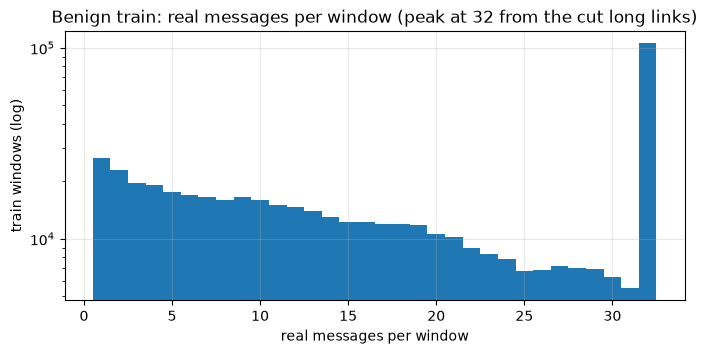

In [5]:
rows = []
lengths = {}
for d in (train, val):
    n = d.mask.sum(1).numpy()
    lengths[d.split] = n
    rows.append(
        {
            "split": d.split,
            "min": int(n.min()),
            "median": float(np.median(n)),
            "mean": round(float(n.mean()), 2),
            "max": int(n.max()),
            "share = 32": round(float((n == 32).mean()), 3),
            "share 1-3": round(float((n <= 3).mean()), 3),
            "share 1 (no recon target)": round(float((n < 2).mean()), 3),
            "padding share": round(1 - float(d.mask.float().mean()), 3),
        }
    )
display(pd.DataFrame(rows).set_index("split"))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(lengths["train"], bins=np.arange(1, 34) - 0.5, color="tab:blue")
ax.set_xlabel("real messages per window")
ax.set_ylabel("train windows (log)")
ax.set_yscale("log")
ax.set_title("Benign train: real messages per window (peak at 32 from the cut long links)")
plt.show()

Per-feature statistics over the **real** train rows, in the stored scaling (benign train z-scores from
`metadata.json`, so ≈ 0 / 1). The trainer re-expresses `claimed_pos_x/y` and `range` with median / IQR and a soft
tail (D13); that scaling is shown in section 3.

In [6]:
real = train.x[train.mask].numpy()
pd.DataFrame({"mean": real.mean(0), "std": real.std(0), "min": real.min(0), "max": real.max(0)}, index=FEATURES).round(
    3
)

,mean,std,min,max
claimed_pos_x,-0.0,1.000,-1.156,2.359000
claimed_pos_y,0.0,0.991,-2.014,2.368000
rx_pos_x,-0.0,1.000,-1.156,2.359000
rx_pos_y,0.0,0.991,-2.014,2.367000
claimed_vel_x,0.0,0.993,-2.546,2.553000
claimed_vel_y,0.0,0.998,-2.296,2.232000
rx_vel_x,0.0,0.993,-2.630,2.570000
rx_vel_y,-0.0,0.998,-2.331,2.227000
claimed_acl_x,-0.0,0.994,-5.179,5.180000
claimed_acl_y,-0.0,0.994,-3.719,3.749000


One train window: the first full (32-row) window of the train split, as a heat map of its 13 features (stored scaling).

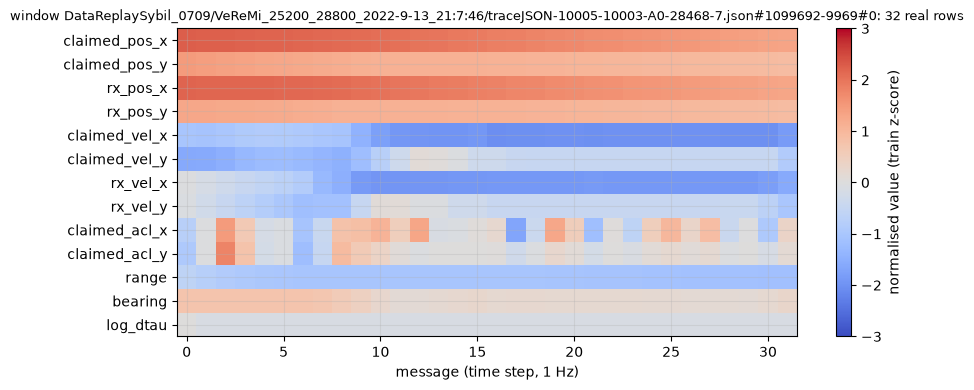

In [7]:
i = int(np.flatnonzero(lengths["train"] == 32)[0])
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(train.x[i].numpy().T, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.set_xlabel("message (time step, 1 Hz)")
ax.set_title(f"window {train.ids[i]}: {lengths['train'][i]} real rows", fontsize=9)
fig.colorbar(im, ax=ax, label="normalised value (train z-score)")
plt.show()
del real, train  # train is not needed again (the evaluation fitted Mahalanobis / kNN on it already)

## 2. Model

The run's settings rebuild `PretrainingModel` (this package's own `heads.py` + `encoder.py`): TimesNet
encoder (token embedding, 4 TimesBlocks, shared LayerNorm) + learned mask token + reconstruction head on H, P1–P3
heads and the SimCLR projection on z. Output shapes are for a batch of 2 full random windows; parameter counts are
asserted against D12 and the run's own preflight in `env.json`.

In [8]:
model_settings = PretrainConfig.from_dict(run.config) if run.config else PretrainConfig.from_dict(vars(defaults))
torch.manual_seed(0)
model = PretrainingModel(model_settings).eval()
table = []
watch = {
    "encoder.embedding": model.encoder.embedding,
    **{f"encoder.blocks.{k}": b for k, b in enumerate(model.encoder.blocks)},
    "recon_head": model.recon_head,
    **{f"physics_heads.{k}": h for k, h in model.physics_heads.heads.items()},
    "proj_head": model.proj_head,
}
hooks = [
    m.register_forward_hook(
        lambda mod, inp, out, name=name: table.append(
            (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))
        )
    )
    for name, m in watch.items()
]
x0 = torch.randn(2, model_settings.seq_len, model_settings.n_features)
m0 = torch.ones(2, model_settings.seq_len, dtype=torch.bool)
with torch.no_grad():
    h0, z0 = model.encoder(x0, m0)
    model.recon_head(h0)
    model.physics_heads(z0)
    model.proj_head(z0)
for h in hooks:
    h.remove()
table.insert(
    len(watch) - 5,
    (
        "encoder.norm (shared)",
        "LayerNorm",
        tuple(h0.shape[1:]),
        sum(p.numel() for p in model.encoder.norm.parameters()),
    ),
)
table.append(("mask_token", "Parameter", (model_settings.n_features,), model.mask_token.numel()))
display(pd.DataFrame(table, columns=["module", "type", "output (per window)", "params"]))

params_encoder = sum(p.numel() for p in model.encoder.parameters())
params_total = sum(p.numel() for p in model.parameters())
pre = run.env.get("preflight", {})
print(
    f"encoder {params_encoder:,} | total with heads + mask token {params_total:,} | H {tuple(h0.shape[1:])}, "
    f"z {tuple(z0.shape[1:])}"
)
print(
    "env.json preflight:",
    {k: pre.get(k) for k in ("params_encoder", "params_total")},
    "| summary.json:",
    {k: run.summary.get(k) for k in ("params_encoder", "params_total")},
)
assert params_encoder == EXPECTED_ENCODER_PARAMS and params_total == EXPECTED_TOTAL_PARAMS, (
    params_encoder,
    params_total,
)
assert (
    pre.get("params_encoder", params_encoder) == params_encoder
    and pre.get("params_total", params_total) == params_total
)

,module,type,output (per window),params
0,encoder.embedding,TokenEmbedding,"(32, 128)",4992
1,encoder.blocks.0,TimesBlock,"(32, 128)",574016
2,encoder.blocks.1,TimesBlock,"(32, 128)",574016
3,encoder.blocks.2,TimesBlock,"(32, 128)",574016
4,encoder.blocks.3,TimesBlock,"(32, 128)",574016
5,encoder.norm (shared),LayerNorm,"(32, 128)",256
6,recon_head,ReconstructionHead,"(32, 13)",18189
7,physics_heads.p1_speed_jump,Sequential,"(1,)",16641
8,physics_heads.p2_speed_scaled,Sequential,"(1,)",16641
9,physics_heads.p3_sharp_turn,Sequential,"(1,)",16641


encoder 2,301,312 | total with heads + mask token 2,402,461 | H (32, 128), z (128,)
env.json preflight: {'params_encoder': 2301312, 'params_total': 2402461} | summary.json: {'params_encoder': 2301312, 'params_total': 2402461}


Objectives and their weights (D7: λ_recon = 1, λ_NT-Xent and λ_P1–P3 = 0.3; each raw loss is divided by a running
scale frozen after `norm_warmup_steps`), plus the run's preflight checks (every `padding_invariance_*` must be 0:
padding rows may not change any loss or z).

In [9]:
keys = [
    "use_recon",
    "use_nce",
    "use_physics",
    "lambda_recon",
    "lambda_nce",
    "lambda_p1",
    "lambda_p2",
    "lambda_p3",
    "recon_ratio",
    "block_ratio",
    "temperature",
    "inject_prob",
    "min_rows_aux",
    "norm_warmup_steps",
    "robust_features",
    "soft_clip",
    "length_bucketed",
    "batch_size",
    "lr",
    "weight_decay",
    "warmup_steps",
    "grad_clip",
    "max_epochs",
    "max_steps",
    "patience",
    "seed",
    "min_train_rows",
    "short",
    "device",
]
display(
    pd.Series({k: run.config.get(k, "(not in config.json)") for k in keys}, name="config.json", dtype=object).to_frame()
)
if pre:
    display(pd.Series(pre, name="env.json preflight", dtype=object).to_frame())
    bad = {k: v for k, v in pre.items() if k.startswith("padding_invariance") and abs(v) > 1e-5}
    print("padding invariance:", "OK (all 0)" if not bad else f"NOT ZERO {bad}")
else:
    plots.note("env.json has no preflight block")

,config.json
use_recon,True
use_nce,True
use_physics,True
lambda_recon,1.0
lambda_nce,0.3
lambda_p1,0.3
lambda_p2,0.3
lambda_p3,0.3
recon_ratio,0.25
block_ratio,"[0.2, 0.3]"


,env.json preflight
padding_invariance_recon,0.0
padding_invariance_nce,0.0
padding_invariance_p1,0.0
padding_invariance_p2,0.0
padding_invariance_p3,0.0
nce_masked_pairs_first64,40
scaling_roundtrip_max_abs,0.0
padding_invariance_z,0.0
inject_share_of_valid,0.576923
params_encoder,2301312


padding invariance: OK (all 0)


## 3. Training record

What the trainer wrote: `summary.json` (stop reason, best epoch by **benign val joint loss**, label-free), the
environment (device, GPU, label files opened = 0, the D13 scaling) and the first / last lines of `train.log`.

In [10]:
if run.summary:
    print(json.dumps(run.summary, indent=2))
else:
    plots.note("no summary.json (run still going or stopped before writing it)")
env_keys = [
    "device",
    "cuda_device_name",
    "cuda_total_memory_gb",
    "torch",
    "python",
    "git_commit",
    "git_dirty",
    "label_files_opened",
    "label_paths_refused",
    "files_opened",
    "splits_opened",
    "load_seconds",
    "data_selection",
]
display(pd.Series({k: run.env.get(k) for k in env_keys if k in run.env}, name="env.json", dtype=object).to_frame())
scaling = run.env.get("scaling") or {}
if scaling:
    display(pd.DataFrame(scaling).T)
if run.log:
    print("\n".join(run.log if len(run.log) <= 12 else run.log[:4] + ["..."] + run.log[-6:]))

{
  "run_id": "model-t32b-seed0",
  "seed": 0,
  "params_encoder": 2301312,
  "params_total": 2402461,
  "best_epoch": 20,
  "best_val_joint": 0.3141556475187995,
  "epochs_run": 20,
  "steps": 37220,
  "real_updates": 37220,
  "planned_updates": 37220,
  "stop_reason": "max_epochs",
  "wall_seconds": 29449.7,
  "device": "cuda",
  "train_windows": 502773,
  "val_windows": 65313,
  "eval_windows": 8192,
  "min_train_rows": 1,
  "short": false,
  "final_lr": 0.0
}


,env.json
device,cuda
cuda_device_name,Tesla T4
cuda_total_memory_gb,15.652
torch,2.14.1+cu126
python,3.14.5
git_commit,0c104ef27176b2fc15b4d01982d6054318c42434
git_dirty,False
label_files_opened,0
label_paths_refused,0
files_opened,8


,method,median,iqr,soft_clip,mean,std
claimed_pos_x,median / IQR + soft tail,251.114105,668.015747,5.0,NaN,NaN
claimed_pos_y,median / IQR + soft tail,690.999329,519.560822,5.0,NaN,NaN
rx_pos_x,train z-score,NaN,NaN,NaN,475.616455,390.23526
rx_pos_y,train z-score,NaN,NaN,NaN,638.47876,304.983887
claimed_vel_x,train z-score,NaN,NaN,NaN,0.09005,7.078862
claimed_vel_y,train z-score,NaN,NaN,NaN,0.254468,8.127957
rx_vel_x,train z-score,NaN,NaN,NaN,0.004032,7.067833
rx_vel_y,train z-score,NaN,NaN,NaN,0.2384,8.153574
claimed_acl_x,train z-score,NaN,NaN,NaN,0.003393,0.869554
claimed_acl_y,train z-score,NaN,NaN,NaN,-0.016127,1.205732


2026-11-16 03:32:05,761 INFO run folder src/runs/pretraining/all/T32_benign/model-t32b-seed0 (dataset t32b, T = 32)
2026-11-16 03:32:05,873 INFO CUDA: memory guard budget 14.07 GB (85% of 16.5 GB system RAM; mem_gb 22.0 exceeds it); it watches host RSS only, GPU memory is logged per eval
2026-11-16 03:32:17,238 INFO loaded train 502773 / val 65313 windows in 0.7 s; device cuda
2026-11-16 03:32:22,786 INFO preflight ok: {"padding_invariance_recon": 0.0, "padding_invariance_nce": 0.0, "padding_invariance_p1": 0.0, "padding_invariance_p2": 0.0, "padding_invariance_p3": 0.0, "nce_masked_pairs_first64": 40, "scaling_roundtrip_max_abs": 1.1920928955078125e-07, "padding_invariance_z": 0.0, "inject_share_of_valid": 0.5769230723381042, "params_encoder": 2301312, "params_total": 2402461}
...
step 37050/37220 ep 19 joint 0.4449 recon 0.1852 nce 0.3281 p1 0.0742 p2 0.0167 p3 0.0190 | 0.54s/step mem 4.14 GB
step 37100/37220 ep 19 joint 0.5786 recon 0.3313 | 0.36s/step mem 4.14 GB
step 37150/37220 e

### 3a. Every loss, train vs val per epoch

Train = mean over the epoch's updates (a loss's mean uses only the updates where it was present: length-bucketed
batches of very short windows can lack NT-Xent / P-head losses); val = the benign val check set (epoch 0 = random
init, no train value). Dotted line on P1–P3 = chance BCE (ln 2). Red = best epoch (lowest val joint).

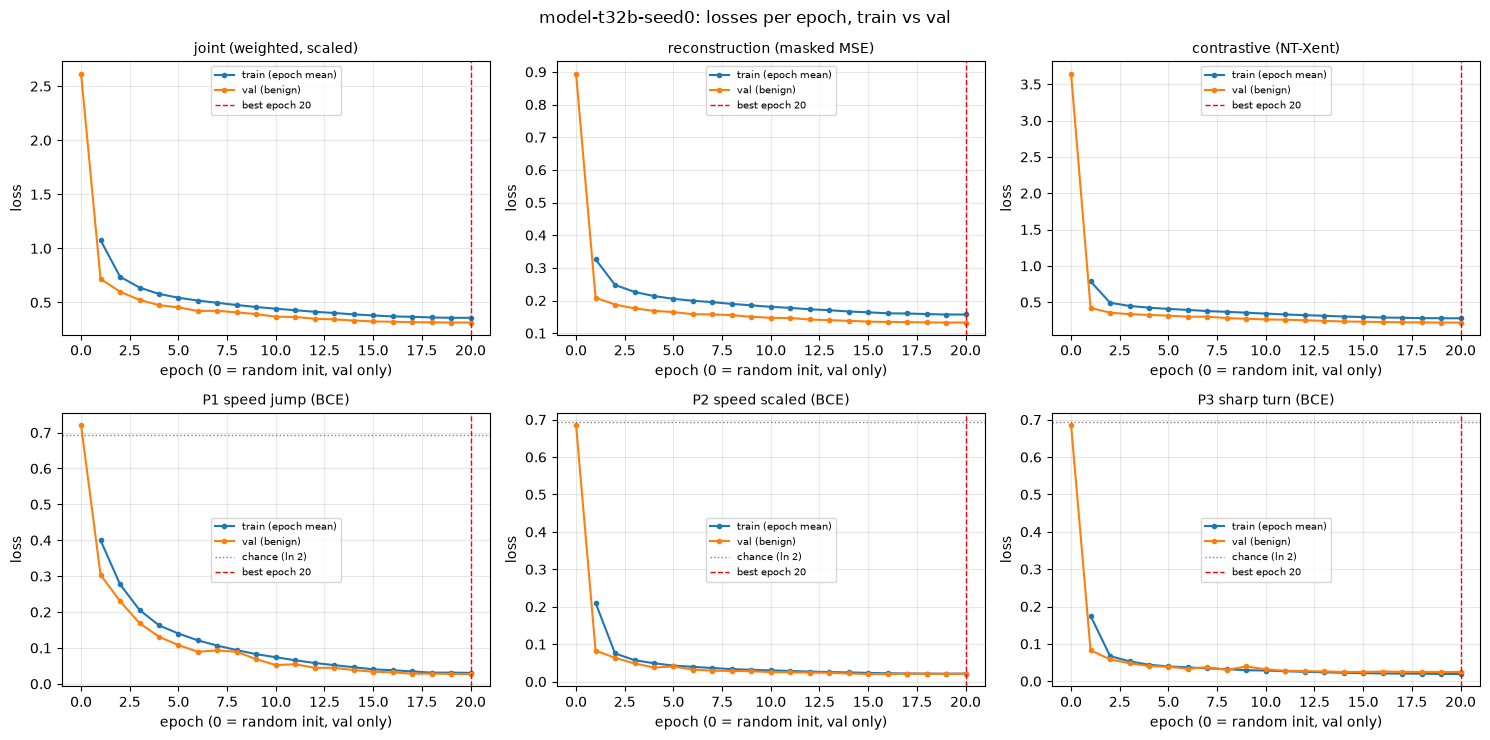

,step,lr,train_joint,val_joint,train_recon,val_recon,val_recon_interp_baseline,train_nce,val_nce,val_p1,val_p2,val_p3,train_steps,train_skipped,grad_norm_mean,grad_norm_max,is_best,bad_epochs,partial
epoch,,,,,,,,,,,,,,,,,,,
0,0,0.0000,NaN,2.6146,NaN,0.8943,0.2933,NaN,3.6436,0.7204,0.6848,0.6852,0,0,NaN,NaN,False,0,False
1,1861,0.0010,1.0759,0.7176,0.3264,0.2086,0.2933,0.7869,0.4203,0.3035,0.0831,0.0830,1861,0,0.6884,2.0027,True,0,False
2,3722,0.0010,0.7381,0.5996,0.2476,0.1877,0.2933,0.4927,0.3557,0.2304,0.0636,0.0585,1861,0,0.6141,2.1049,True,0,False
3,5583,0.0010,0.6378,0.5240,0.2263,0.1758,0.2933,0.4484,0.3351,0.1692,0.0487,0.0481,1861,0,0.6175,2.5605,True,0,False
4,7444,0.0009,0.5792,0.4754,0.2136,0.1683,0.2933,0.4246,0.3251,0.1312,0.0378,0.0405,1861,0,0.6178,1.6259,True,0,False
5,9305,0.0009,0.5437,0.4544,0.2052,0.1645,0.2933,0.4075,0.3150,0.1077,0.0405,0.0388,1861,0,0.6222,1.8221,True,0,False
6,11166,0.0008,0.5176,0.4211,0.1992,0.1580,0.2933,0.3941,0.3008,0.0894,0.0322,0.0332,1861,0,0.6254,2.7052,True,0,False
7,13027,0.0007,0.4968,0.4230,0.1950,0.1574,0.2933,0.3778,0.3002,0.0930,0.0293,0.0377,1861,0,0.6258,2.2462,False,1,False
8,14888,0.0007,0.4761,0.4082,0.1895,0.1551,0.2933,0.3677,0.2819,0.0892,0.0286,0.0302,1861,0,0.6281,3.6928,True,0,False


In [11]:
show(plots.TrainingPlots(run).losses())
cols = [
    c
    for c in [
        "epoch",
        "step",
        "lr",
        "train_joint",
        "val_joint",
        "train_recon",
        "val_recon",
        "val_recon_interp_baseline",
        "train_nce",
        "val_nce",
        "val_p1",
        "val_p2",
        "val_p3",
        "train_steps",
        "train_skipped",
        "grad_norm_mean",
        "grad_norm_max",
        "is_best",
        "bad_epochs",
        "partial",
    ]
    if c in run.history
]
if cols:
    display(run.history[cols].set_index("epoch").round(4))

### 3b. Reconstruction vs the linear-interpolation baseline (val)

The free baseline fills each hidden row by linear interpolation from its visible neighbours (same hidden rows). A
useful reconstruction must go **below** it; above it, the encoder is worse than a ruler. The baseline is computed
once on the first evaluation's seeded val masks (so it is flat) and pools over hidden rows, while `val_recon` averages
per-batch MSEs: close, not identical, definitions. The val check uses `eval_windows` val windows (summary.json).

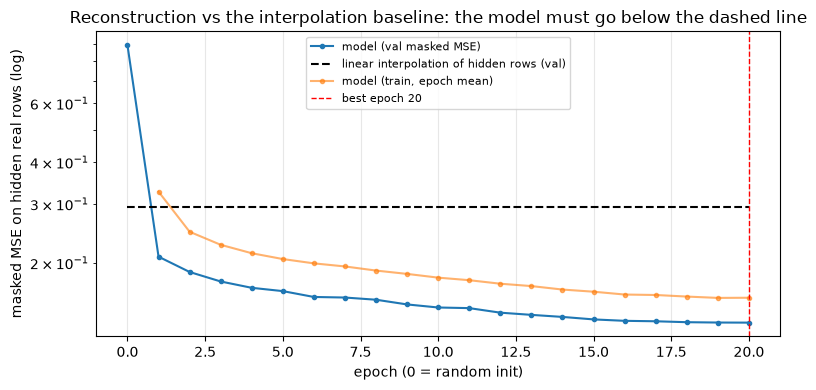

best epoch 20: val recon 0.1325 vs interpolation 0.2933 (ratio 0.452; below 1 = better than interpolation)


In [12]:
show(plots.TrainingPlots(run).recon_vs_interpolation())
h = run.history
if {"val_recon", "val_recon_interp_baseline"} <= set(h.columns) and run.best_epoch is not None:
    row = h[h.epoch == run.best_epoch].iloc[0]
    print(
        f"best epoch {run.best_epoch}: val recon {row.val_recon:.4f} vs interpolation {row.val_recon_interp_baseline:.4f}"
        f" (ratio {row.val_recon / row.val_recon_interp_baseline:.3f}; below 1 = better than interpolation)"
    )

### 3c. Per-update curves

From `steps.jsonl`: each loss per optimiser update (faint) and its rolling mean, the learning rate (warm-up then
cosine to its floor at the last planned update, X1) overlaid on the joint panel and alone, and the pre-clip gradient
norm with the clip value.

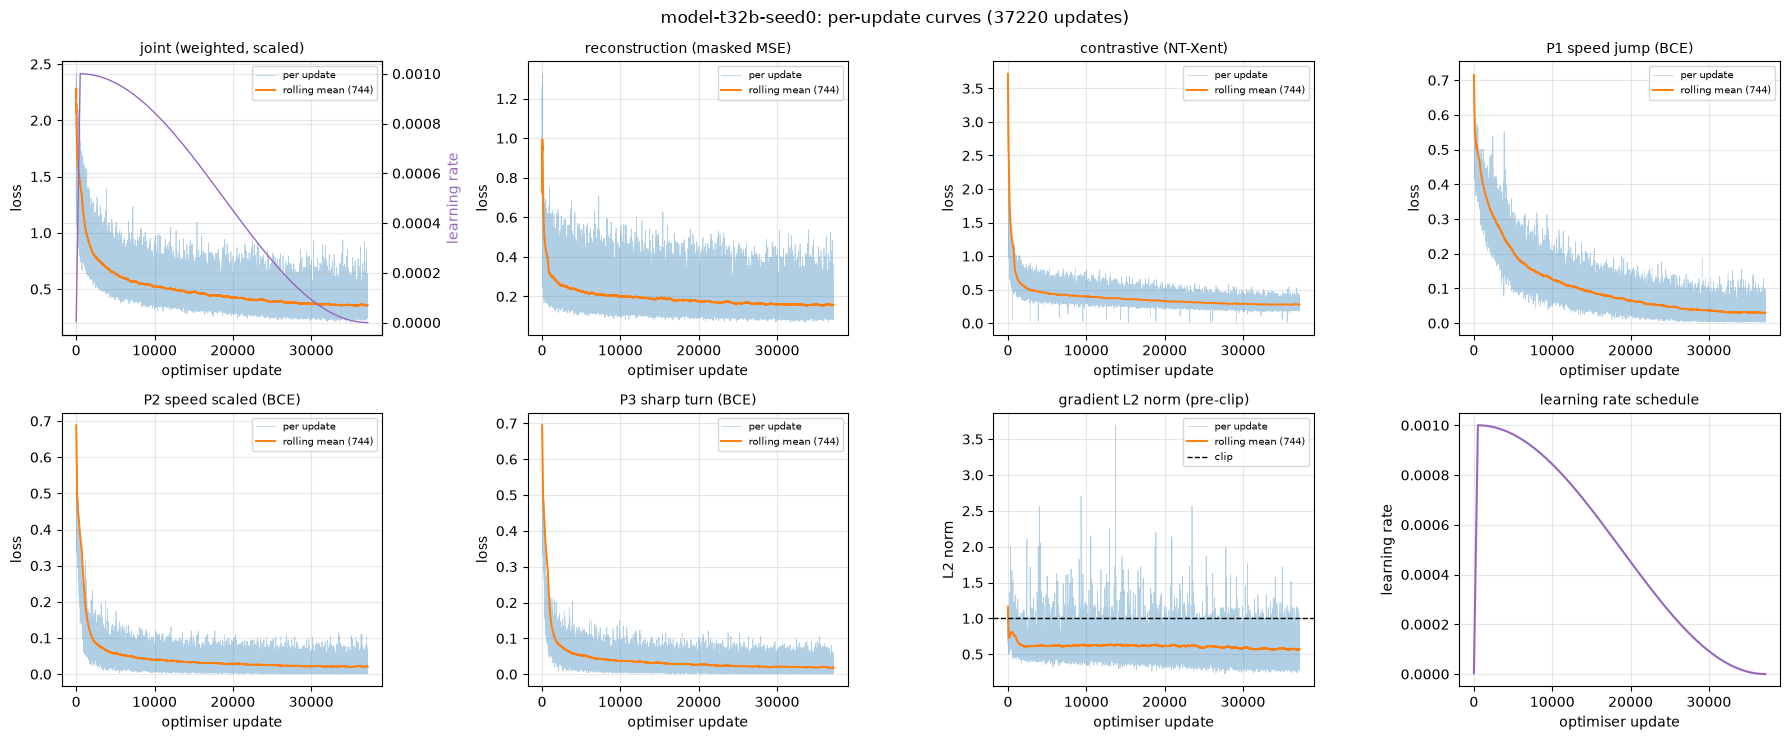

updates 37,220; LR first / max / last 4e-06 / 0.001 / 0; median s/update 0.741
updates without a value, per loss: {'joint': 0, 'recon': 0, 'nce': 3300, 'p1': 3300, 'p2': 3300, 'p3': 3300}


In [13]:
show(plots.TrainingPlots(run).steps())
s = run.steps
if not s.empty:
    print(
        f"updates {len(s):,}; LR first / max / last {s.lr.iloc[0]:.3g} / {s.lr.max():.3g} / {s.lr.iloc[-1]:.3g}; "
        f"median s/update {s.step_seconds.median():.3f}"
        if "step_seconds" in s
        else ""
    )
    print("updates without a value, per loss:", {k: int(s[k].isna().sum()) for k in plots.LOSSES if k in s})

### 3d. Physics heads P1–P3: injected-violation detection on val

P1 (speed jump), P2 (speed scaled), P3 (sharp turn) are trained to detect violations **we inject** into benign windows
(D4). AUROC on val: 0.5 = guessing. This measures the pretext task, not attack detection.

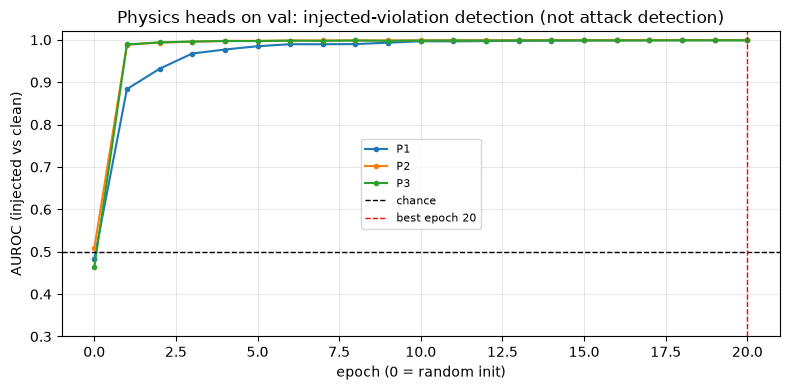

In [14]:
show(plots.TrainingPlots(run).physics_auroc())

### 3e. Representation health

Collapse monitors: effective rank of z (how many directions z uses; max d = 128), z std per dimension (mean / min),
alignment / uniformity, cosine of two views of the same window (`cos_pos`, should stay high) vs other windows
(`cos_neg`, should fall). Length shortcut: `length_probe_r2` (ridge R² of the real-row count from z; near 1 = length is
plainly readable from z) and `corr_znorm_length`. A high R² is why every test AUROC in section 5 sits next to the
length-only reference.

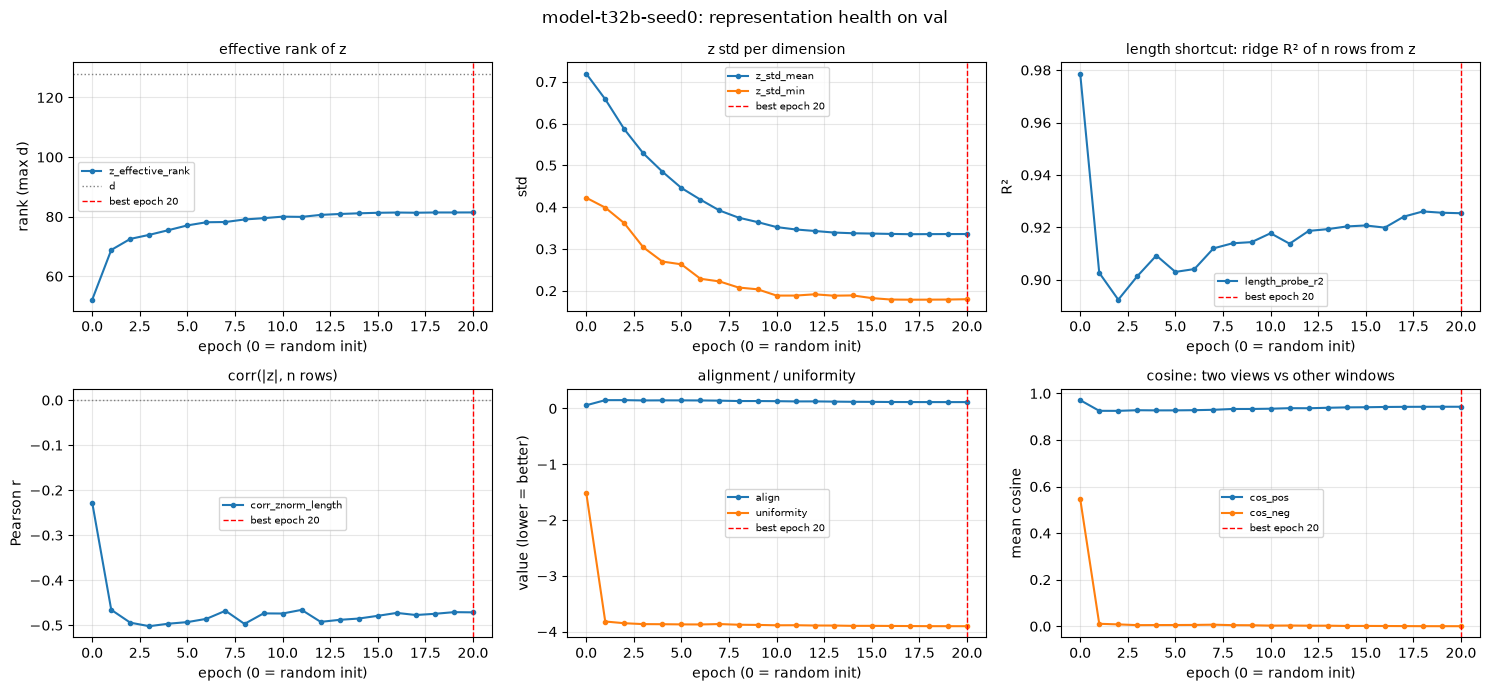

In [15]:
show(plots.TrainingPlots(run).representation())

### 3f. Time and memory

Training and evaluation minutes per epoch (history), and the memory recorded at each evaluation (MPS driver / process
RSS on the Mac; CUDA peak allocated / reserved on EC2).

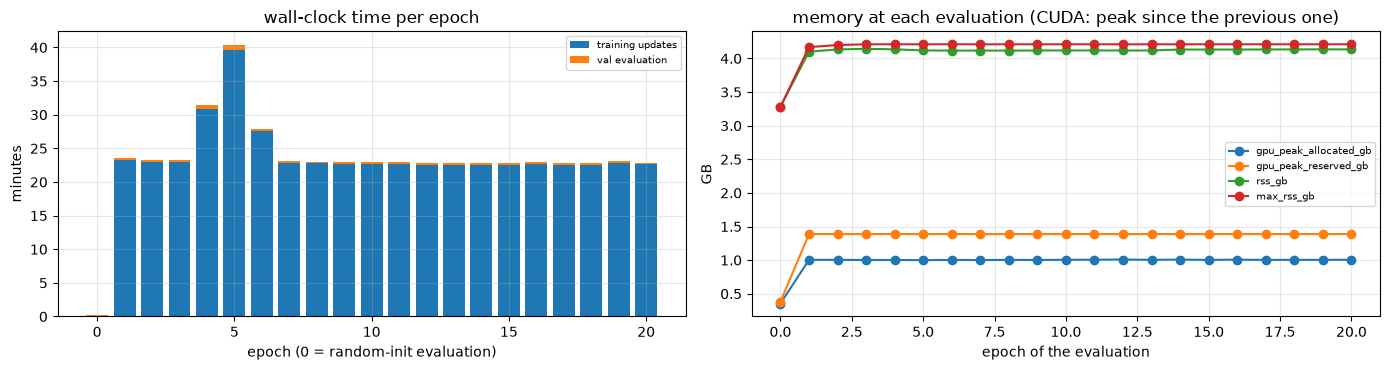

In [16]:
show(plots.TrainingPlots(run).time_memory())

### 3g. Loss normalisation scales

Each raw loss is divided by a running scale (D7) that is frozen after the warm-up; the scales say how large each raw
loss was when they froze.

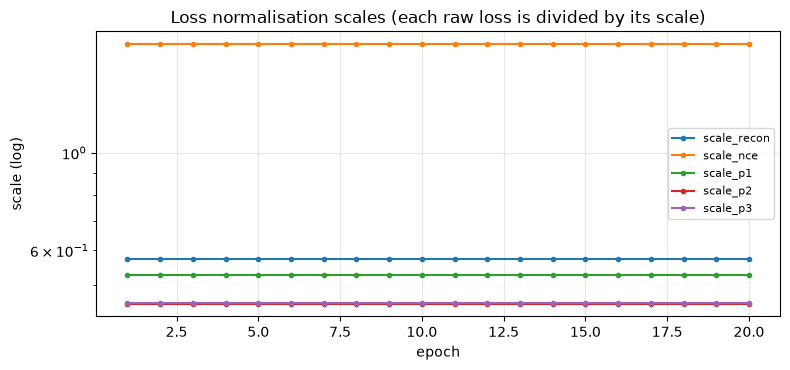

In [17]:
show(plots.TrainingPlots(run).loss_scales())

## 4. Reconstruction on val

Per-feature reconstruction error on the hidden rows over epochs (`feature_history.jsonl`): train (pooled over every
hidden real row of the epoch's training batches, train mode), val, and the val interpolation baseline on the same
hidden rows. Values are in the trained scaling (D13). Red = best epoch.

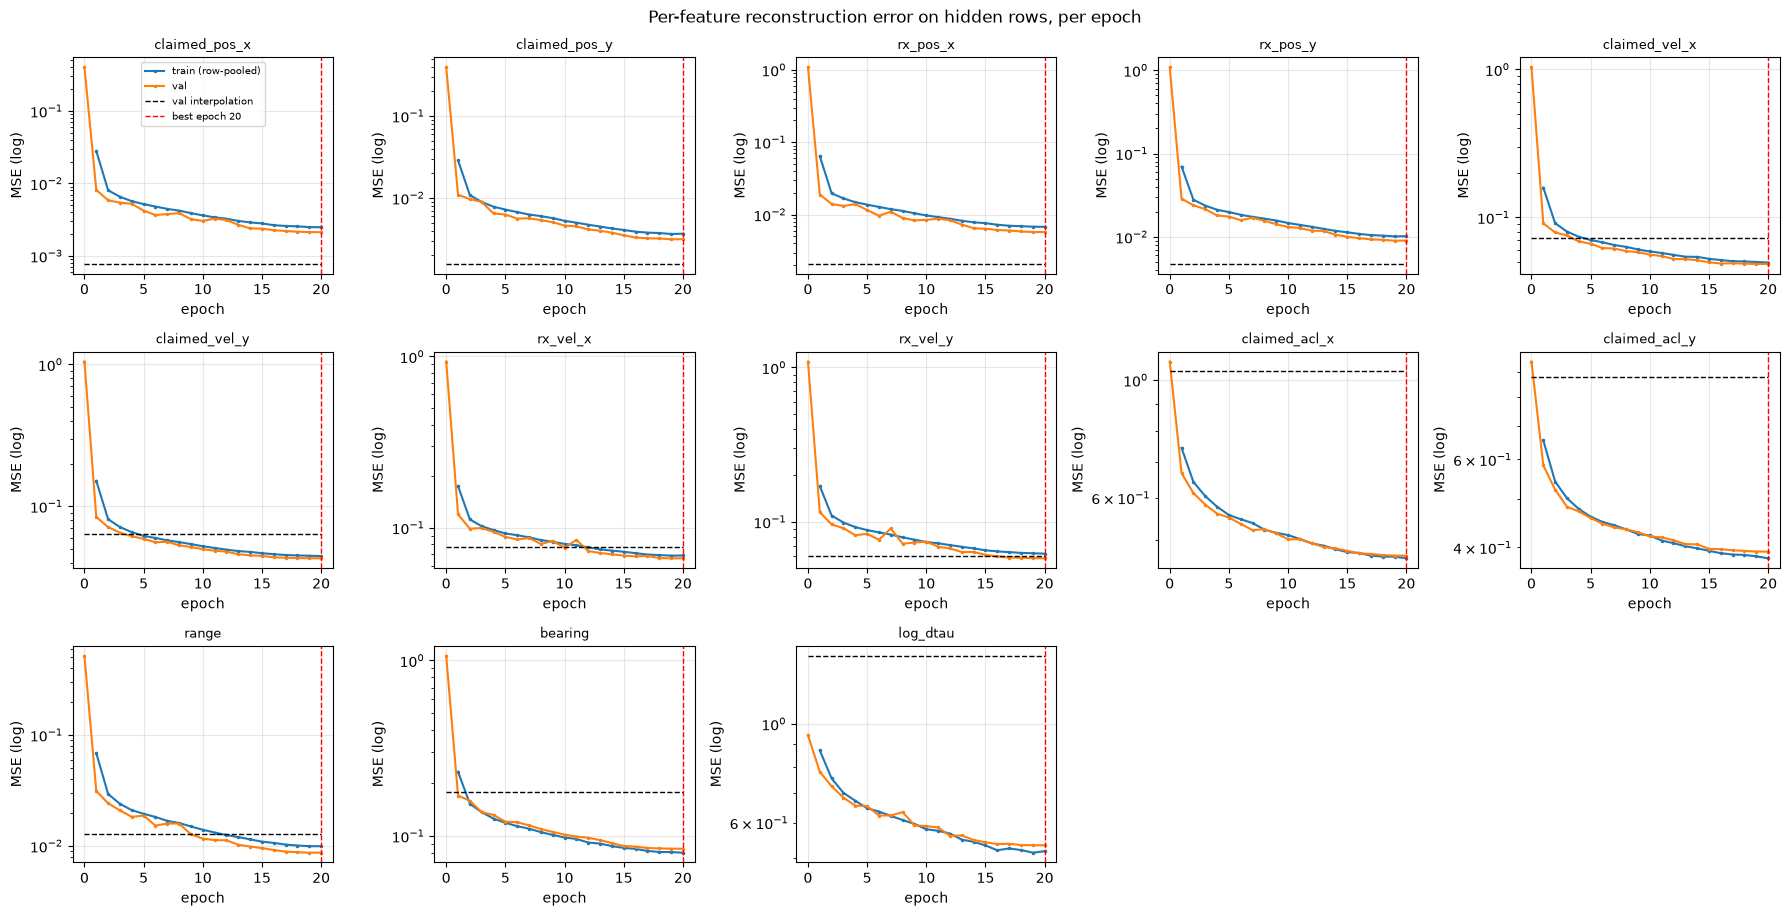

In [18]:
feature_plots = plots.FeaturePlots(run, FEATURES)
show(feature_plots.curves())

Per-feature val error at the best epoch next to the interpolation baseline (ratio < 1: the model beats interpolation
on that feature).

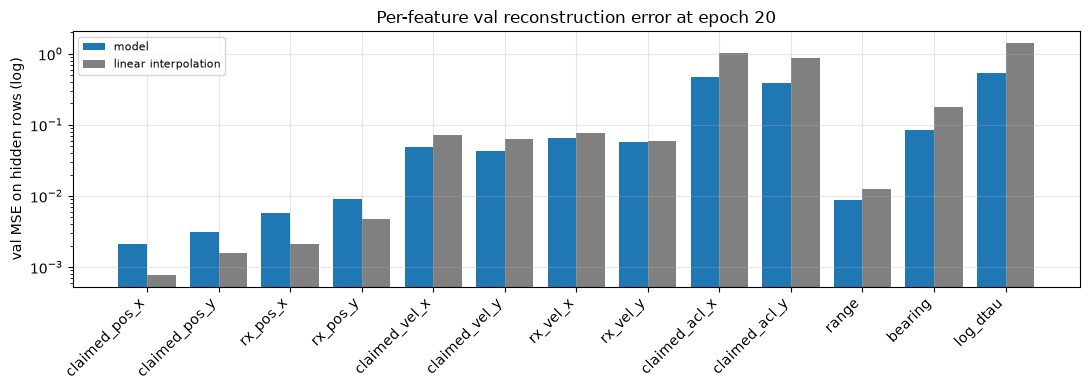

,model (val),interpolation (val),model / interpolation
log_dtau,0.5338,1.4199,0.3759
claimed_acl_x,0.4667,1.0406,0.4485
claimed_acl_y,0.3923,0.8788,0.4463
bearing,0.0847,0.1789,0.4731
rx_vel_x,0.0663,0.0772,0.8583
rx_vel_y,0.0580,0.0599,0.9691
claimed_vel_x,0.0485,0.0723,0.6704
claimed_vel_y,0.0430,0.0633,0.6785
rx_pos_y,0.0090,0.0047,1.9085
range,0.0087,0.0127,0.6836


In [19]:
fig, per_feature = feature_plots.best_bar()
show(fig)
if per_feature is not None:
    display(per_feature.sort_values("model (val)", ascending=False).round(4))

Three full (32-row) val windows (seeded pick) through `best.pt` on the CPU: the package's `ReconMasker` hides rows
(seeded), the encoder sees the mask token there, the reconstruction head predicts every row. Shaded = hidden rows;
crosses = linear interpolation of the hidden rows. Values in the trained scaling.

checkpoint epoch 20, step 37220; windows: ['DoSRandomSybil_0709/VeReMi_25200_28800_2022-9-13_21:8:11/traceJSON-10683-10681-A0-28661-7.json#10108092-10809#2', 'DoSRandomSybil_0709/VeReMi_28800_32400_2022-9-13_21:8:11/traceJSON-17517-17515-A0-30610-8.json#10175053-17505#0', 'GridSybil_0709/VeReMi_28800_32400_2025-11-15_13:57:9/traceJSON-24555-24553-A16-29615-8.json#10245972-24597#0']
masked MSE of the hidden rows per window: [0.0018 0.0489 0.6635]


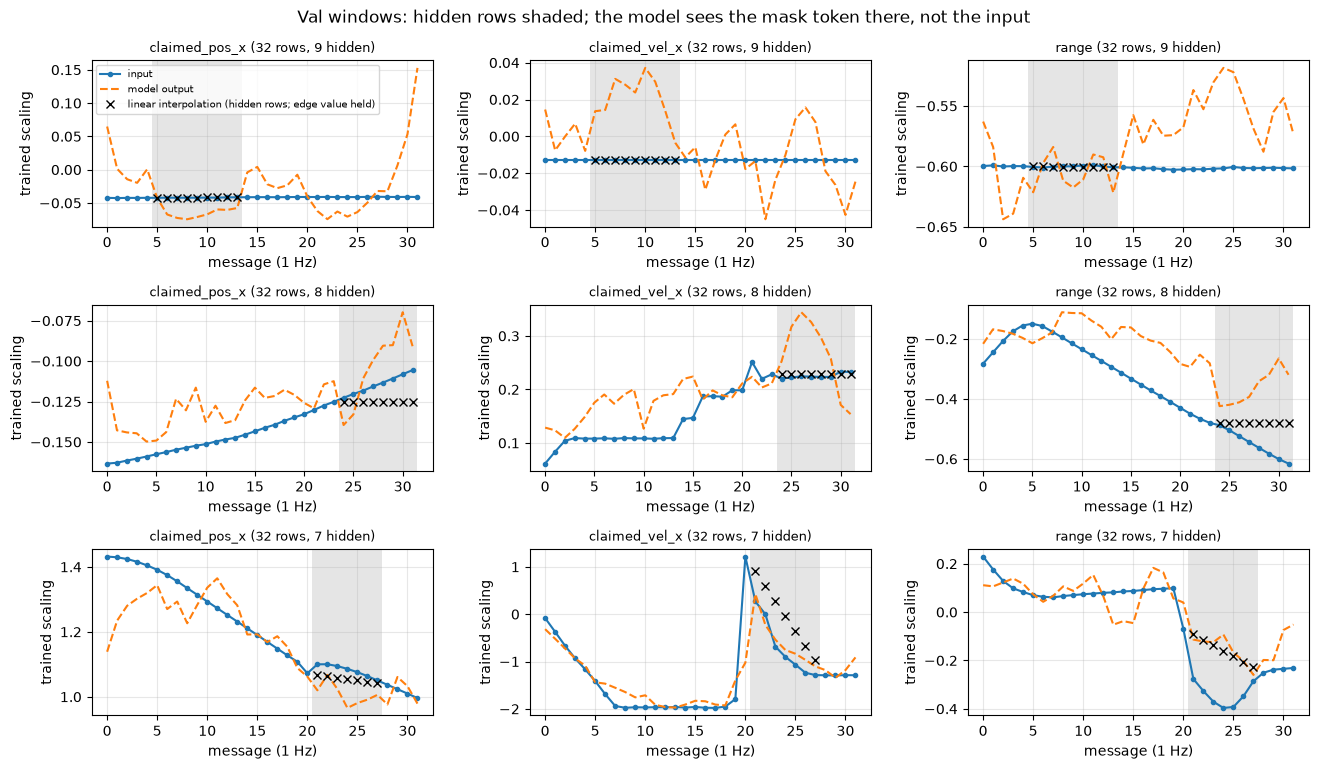

In [20]:
best_pt = run.path / "best.pt"
if best_pt.is_file():
    examples = plots.ReconExamples(best_pt, META)
    full = np.flatnonzero(val.mask.sum(1).numpy() == 32)
    picks = np.sort(np.random.default_rng(0).choice(full, size=min(3, len(full)), replace=False))
    out = examples.run(val.x[picks], val.mask[picks], seed=0)
    print(f"checkpoint epoch {examples.epoch}, step {examples.step}; windows:", [val.ids[i] for i in picks])
    err = ((out["pred"] - out["x"]) ** 2 * out["hidden"][..., None]).sum((1, 2)) / (out["hidden"].sum(1) * 13)
    print("masked MSE of the hidden rows per window:", np.round(err, 4))
    show(
        plots.ReconExamples.plot(
            out, FEATURES, ["claimed_pos_x", "claimed_vel_x", "range"], [val.ids[i] for i in picks]
        )
    )
else:
    plots.note(f"{best_pt} missing")

## 5. Test

**Scores first, labels after.** `evaluate.py` scored every window with the frozen best checkpoint (masked
reconstruction error averaged over seeded mask passes; Mahalanobis on z fitted on benign train z; kNN cosine distance
to a benign train memory bank, K = 5 / 10 / 20 fixed in advance), saved `scores/<split>.npz`, and only then opened the
`_info` label shards (aligned by window id; every attack split must hold its own code only). Thresholds come from
benign val. This notebook reads the saved scores and the summary; the class of a window is its split (benign `test`
vs `test_<attack>`), which evaluate's label check confirmed. Windows with < 2 real rows have nothing to hide: their
reconstruction score is the benign val median (filled, not measured).

In [21]:
if ev is None:
    plots.note("no evaluation folder yet: run `npm run t32b:eval` (and `t32b:eval:random-init`), then re-run")
else:
    checks = ev.label_checks()
    display(pd.Series(checks, name=ev.path.name, dtype=object).to_frame())
    assert checks["labels_read_after_scores"] is True, "labels were not read after the scores"
    if ev.smoke:
        print("*** SMOKE EVALUATION: plumbing only, not results ***")
    display(plots.TestPlots(ev).length_mix().round(4))
    print(
        "fits:",
        json.dumps(
            {k: ev.summary.get("fits", {}).get(k) for k in ("train_windows", "mahalanobis", "recon_undefined_fill")}
        ),
    )

,model-t32b-seed0
scores_written_utc,2026-11-16T17:29:12.171783+00:00
labels_first_read_utc,2026-11-16T17:29:12.429902+00:00
labels_read_after_scores,True
alignment checks,all passed
info shards opened,65
metadata problems,[]
smoke (plumbing only),False
weights,checkpoint


,windows,share n < 2 (recon filled),share n ≤ 3,share n ≥ 4
benign val,65313.0,0.0533,0.1394,0.8606
benign test,60142.0,0.0517,0.1392,0.8608
GridSybil,28087.0,0.0840,0.2037,0.7963
DataReplay,76283.0,0.7017,0.9491,0.0509
DoSRandom,199834.0,0.8881,0.9974,0.0026
DoSDisruptive,199826.0,0.8881,0.9974,0.0026


fits: {"train_windows": 502773, "mahalanobis": {"cond": 1830658320656030.5, "shrinkage": 0.01, "max_cond": 1000000.0}, "recon_undefined_fill": {"value": 0.06228781224061281, "rule": "median of the defined benign val errors (label-free); windows with < 2 real rows"}}


AUROC per attack × score × subset (all windows, n ≥ 2 = reconstruction measured, n ≤ 3, n ≥ 4 real rows), each next
to the **length-only** reference on the same windows (score = − real rows, direction fixed in advance, F11), plus the
share of windows whose reconstruction score is filled. The `all` reconstruction AUROC depends on that fill; compare on
n ≥ 2 / n ≥ 4.

In [22]:
if ev is not None:
    auroc = plots.AurocTable.wide(ev.summary)
    display(auroc.round(3))

all              n ≥ 2              n ≤ 3              n ≥ 4             recon fill share       
                           AUROC length only  AUROC length only  AUROC length only  AUROC length only           benign attack
attack        score                                                                                                          
GridSybil     recon        0.741       0.559  0.760       0.549  0.601       0.521  0.772       0.538            0.052  0.084
              mahalanobis  0.880       0.559  0.888       0.549  0.686       0.521  0.892       0.538            0.052  0.084
              knn_k5       0.886       0.559  0.894       0.549  0.788       0.521  0.897       0.538            0.052  0.084
              knn_k10      0.885       0.559  0.892       0.549  0.776       0.521  0.895       0.538            0.052  0.084
              knn_k20      0.884       0.559  0.891       0.549  0.763       0.521  0.893       0.538            0.052  0.084
DataReplay    recon        0.486       0.952  0.469       0.947  0.453       0.711  0.430       0.927            0.052  0.702
              mahalanobis  0.946       0.952  0.934       0.947  0.693       0.711  0.877       0.927            0.052  0.702
              knn_k5       0.840       0.952  0.889       0.947  0.728       0.711  0.863       0.927            0.052  0.702
              knn_k10      0.846       0.952  0.892       0.947  0.711       0.711  0.862       0.927            0.052  0.702
              knn_k20      0.853       0.952  0.896       0.947  0.694       0.711  0.857       0.927            0.052  0.702
DoSRandom     recon        0.550       0.967  0.999       0.964  0.512       0.769  1.000       0.978            0.052  0.888
              mahalanobis  0.960       0.967  0.997       0.964  0.719       0.769  1.000       0.978            0.052  0.888
              knn_k5       0.971       0.967  0.999       0.964  0.919       0.769  1.000       0.978            0.052  0.888
              knn_k10      0.965       0.967  0.999       0.964  0.895       0.769  1.000       0.978            0.052  0.888
              knn_k20      0.957       0.967  0.999       0.964  0.863       0.769  1.000       0.978            0.052  0.888
DoSDisruptive recon        0.549       0.967  0.997       0.964  0.511       0.769  0.999       0.978            0.052  0.888
              mahalanobis  0.954       0.967  0.997       0.964  0.683       0.769  1.000       0.978            0.052  0.888
              knn_k5       0.859       0.967  0.997       0.964  0.758       0.769  0.999       0.978            0.052  0.888
              knn_k10      0.860       0.967  0.997       0.964  0.734       0.769  0.999       0.978            0.052  0.888
              knn_k20      0.861       0.967  0.997       0.964  0.705       0.769  0.999       0.978            0.052  0.888

Operating points at the benign val p95 threshold (recall of the attack windows, false-positive rate on the benign test
windows) and PR-AUC with its chance level, on all windows and on n ≥ 4; then per-track AUROC (track = one link, max /
mean of its window scores).

In [23]:
if ev is not None:
    long = plots.AurocTable.long(ev.summary)
    ops = long[long.subset.isin(["all", "n_ge_4"])].set_index(["attack", "score", "subset"])
    display(ops[["AUROC", "PR-AUC", "chance", "recall@p95", "benign FPR@p95", "n benign", "n attack"]].round(3))
    display(plots.AurocTable.tracks(ev.summary).round(3))

AUROC  PR-AUC  chance  recall@p95  benign FPR@p95  n benign  n attack
attack        score       subset                                                                       
GridSybil     recon       all     0.741   0.615   0.318       0.310           0.051     60142     28087
                          n_ge_4  0.772   0.652   0.302       0.337           0.044     51773     22365
              mahalanobis all     0.880   0.843   0.318       0.657           0.051     60142     28087
                          n_ge_4  0.892   0.884   0.302       0.662           0.001     51773     22365
              knn_k5      all     0.886   0.871   0.318       0.717           0.052     60142     28087
                          n_ge_4  0.897   0.887   0.302       0.763           0.037     51773     22365
              knn_k10     all     0.885   0.869   0.318       0.711           0.051     60142     28087
                          n_ge_4  0.895   0.885   0.302       0.758           0.034     51773     22365
              knn_k20     all     0.884   0.867   0.318       0.705           0.049     60142     28087
                          n_ge_4  0.893   0.883   0.302       0.753           0.030     51773     22365
              length_only all     0.559   0.367   0.318       0.000           0.000     60142     28087
                          n_ge_4  0.538   0.333   0.302       0.000           0.000     51773     22365
DataReplay    recon       all     0.486   0.611   0.559       0.027           0.051     60142     76283
                          n_ge_4  0.430   0.090   0.070       0.105           0.044     51773      3883
              mahalanobis all     0.946   0.937   0.559       0.611           0.051     60142     76283
                          n_ge_4  0.877   0.455   0.070       0.113           0.001     51773      3883
              knn_k5      all     0.840   0.842   0.559       0.326           0.052     60142     76283
                          n_ge_4  0.863   0.380   0.070       0.342           0.037     51773      3883
              knn_k10     all     0.846   0.844   0.559       0.315           0.051     60142     76283
                          n_ge_4  0.862   0.366   0.070       0.306           0.034     51773      3883
              knn_k20     all     0.853   0.848   0.559       0.310           0.049     60142     76283
                          n_ge_4  0.857   0.348   0.070       0.261           0.030     51773      3883
              length_only all     0.952   0.934   0.559       0.000           0.000     60142     76283
                          n_ge_4  0.927   0.353   0.070       0.000           0.000     51773      3883
DoSRandom     recon       all     0.550   0.877   0.769       0.112           0.051     60142    199834
                          n_ge_4  1.000   0.984   0.010       1.000           0.044     51773       523
              mahalanobis all     0.960   0.978   0.769       0.638           0.051     60142    199834
                          n_ge_4  1.000   0.992   0.010       1.000           0.001     51773       523
              knn_k5      all     0.971   0.987   0.769       0.844           0.052     60142    199834
                          n_ge_4  1.000   0.977   0.010       1.000           0.037     51773       523
              knn_k10     all     0.965   0.984   0.769       0.747           0.051     60142    199834
                          n_ge_4  1.000   0.977   0.010       1.000           0.034     51773       523
              knn_k20     all     0.957   0.980   0.769       0.602           0.049     60142    199834
                          n_ge_4  1.000   0.976   0.010       1.000           0.030     51773       523
              length_only all     0.967   0.981   0.769       0.000           0.000     60142    199834
                          n_ge_4  0.978   0.188   0.010       0.000           0.000     51773       523
DoSDisruptive recon       all     0.549   0.876   0.769       0.111           0.05

max   mean
attack        score                    
GridSybil     recon        0.719  0.727
              mahalanobis  0.873  0.877
              knn_k5       0.880  0.884
              knn_k10      0.879  0.883
              knn_k20      0.878  0.881
DataReplay    recon        0.434  0.456
              mahalanobis  0.933  0.942
              knn_k5       0.817  0.834
              knn_k10      0.823  0.840
              knn_k20      0.830  0.847
DoSRandom     recon        0.497  0.520
              mahalanobis  0.950  0.958
              knn_k5       0.965  0.970
              knn_k10      0.957  0.963
              knn_k20      0.946  0.954
DoSDisruptive recon        0.497  0.520
              mahalanobis  0.943  0.951
              knn_k5       0.839  0.854
              knn_k10      0.839  0.854
              knn_k20      0.839  0.855

Score histograms per window, benign test vs each attack, with the benign val p95 threshold (dashed). kNN is shown for
K = 10 (all three K are in the tables above).

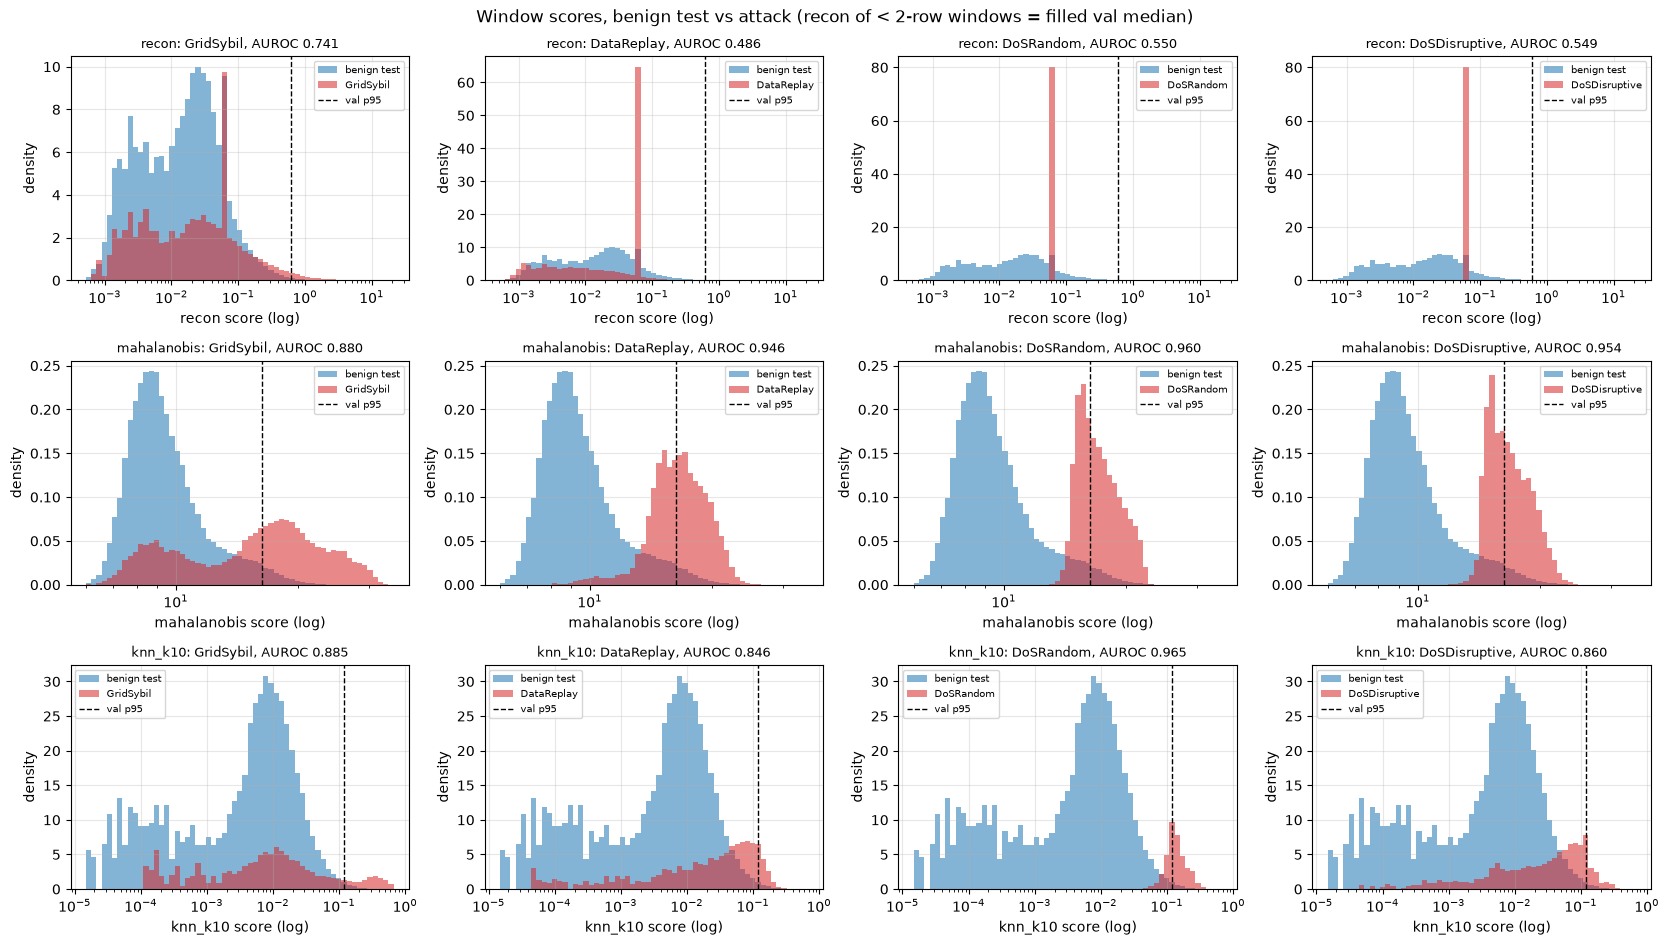

In [24]:
if ev is not None:
    show(plots.TestPlots(ev).histograms(("recon", "mahalanobis", "knn_k10")))

Measured reconstruction error (only windows with ≥ 2 real rows) against the real rows per window: median and IQR band
per length, benign test and each attack. DataReplay / DoS windows are 95–100% 1–3 rows (F11), so their curves rest on
few long windows.

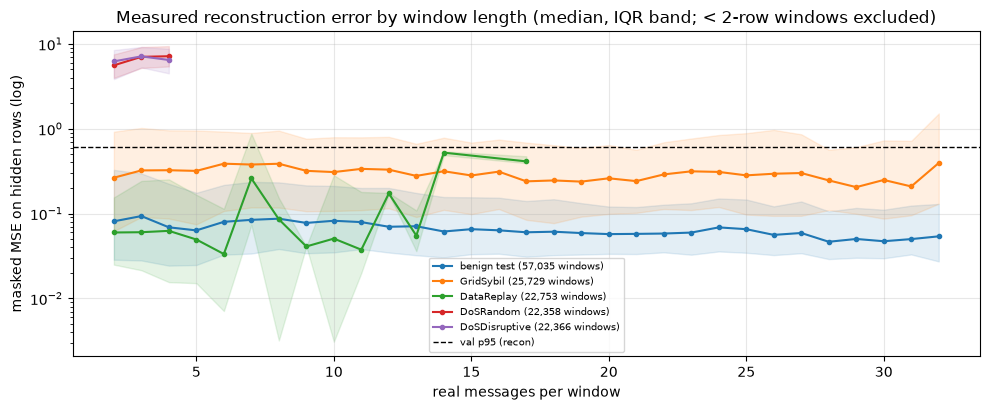

In [25]:
if ev is not None:
    show(plots.TestPlots(ev).recon_by_rows())

Random-init control: the same evaluation with an untrained, seed-fixed TimesNet and the run's scaling (`--random-init`).
An untrained encoder can already separate some attacks (kNN / Mahalanobis on random features, and length). Pretraining
adds what the difference shows, per subset.

In [26]:
if ev is None:
    plots.note("no evaluation of the trained model")
elif ev_random is None:
    plots.note("no random-init evaluation folder: run `npm run t32b:eval:random-init`")
else:
    print("random-init folder:", ev_random.path, "| smoke:", ev_random.smoke)
    a = plots.AurocTable.long(ev.summary).set_index(["attack", "score", "subset"]).AUROC
    b = plots.AurocTable.long(ev_random.summary).set_index(["attack", "score", "subset"]).AUROC
    ctrl = pd.DataFrame({"trained": a, "random init": b, "trained - random": a - b}).reset_index()
    ctrl = ctrl[ctrl.subset.isin(["n_ge_2", "n_ge_4"]) & (ctrl.score != "length_only")]
    display(
        ctrl.pivot_table(
            index=["attack", "score"],
            columns="subset",
            values=["trained", "random init", "trained - random"],
            sort=False,
        ).round(3)
    )

random-init folder: src/runs/evaluation/all/T32_benign/model-t32b-seed0-random-init | smoke: False


trained        random init        trained - random       
subset                     n_ge_2 n_ge_4      n_ge_2 n_ge_4           n_ge_2 n_ge_4
attack        score                                                                
GridSybil     recon         0.760  0.772       0.559  0.569            0.201  0.204
              mahalanobis   0.888  0.892       0.674  0.676            0.214  0.216
              knn_k5        0.894  0.897       0.840  0.845            0.054  0.052
              knn_k10       0.892  0.895       0.832  0.838            0.060  0.057
              knn_k20       0.891  0.893       0.822  0.829            0.069  0.064
DataReplay    recon         0.469  0.430       0.434  0.393            0.035  0.037
              mahalanobis   0.934  0.877       0.908  0.896            0.026 -0.019
              knn_k5        0.889  0.863       0.882  0.871            0.008 -0.007
              knn_k10       0.892  0.862       0.883  0.869            0.009 -0.007
              knn_k20       0.896  0.857       0.884  0.865            0.012 -0.008
DoSRandom     recon         0.999  1.000       0.998  1.000            0.001 -0.000
              mahalanobis   0.997  1.000       0.996  0.999            0.001  0.001
              knn_k5        0.999  1.000       0.990  0.993            0.009  0.007
              knn_k10       0.999  1.000       0.988  0.992            0.010  0.007
              knn_k20       0.999  1.000       0.986  0.992            0.013  0.008
DoSDisruptive recon         0.997  0.999       0.976  0.997            0.022  0.002
              mahalanobis   0.997  1.000       0.993  0.998            0.004  0.001
              knn_k5        0.997  0.999       0.946  0.973            0.050  0.026
              knn_k10       0.997  0.999       0.939  0.970            0.058  0.029
              knn_k20       0.997  0.999       0.929  0.966            0.068  0.034

## 6. Context (not a fair comparison)

The one-class ConvAE `task/autoencoder_benign_t32` (63,293 parameters, z = 16) used the **same split and the same test
windows**, but a different model, objective and scoring: it reconstructs every row without hiding any (so it also
scores 1-row windows), while TimesNet's reconstruction score is measured only on windows with ≥ 2 real rows and filled
below that. Its numbers are read from disk (the stored output of its notebook's results cell, else
`baselinepaper/01-our-studies/results.json`), never typed in. The like-for-like comparison is **GridSybil on n ≥ 4**
(the ConvAE's ">= 4 rows" AUROC); every other cell differs in subset or score definition. One seed each.

In [27]:
baseline = plots.BaselineContext.load()
if baseline is None:
    plots.note("task/autoencoder_benign_t32 results not found on disk")
elif ev is None:
    plots.note("no TimesNet evaluation to put next to the baseline")
else:
    print("baseline source:", baseline.source)
    display(baseline.compare(ev.summary).round(3))

baseline source: task/autoencoder_benign_t32/autoencoder_benign_T32.ipynb (stored output of the results cell)


ConvAE all  TimesNet all  ConvAE n ≥ 4  TimesNet n ≥ 4
attack        score                                                              
GridSybil     recon             0.736         0.741         0.778           0.772
              mahalanobis       0.510         0.880         0.540           0.892
              length_only       0.559         0.559           NaN           0.538
DataReplay    recon             0.391         0.486         0.349           0.430
              mahalanobis       0.336         0.946         0.295           0.877
              length_only       0.952         0.952           NaN           0.927
DoSRandom     recon             0.973         0.550         1.000           1.000
              mahalanobis       0.837         0.960         0.999           1.000
              length_only       0.967         0.967           NaN           0.978
DoSDisruptive recon             0.611         0.549         1.000           0.999
              mahalanobis       0.556         0.954         0.999           1.000
              length_only       0.967         0.967           NaN           0.978

The numbers the analysis below refers to, computed from the files above (nothing typed in).

In [28]:
key = {
    "run": run.run_id,
    "short run": run.is_short(),
    "evaluation": ev.path.name if ev else None,
    "smoke evaluation": ev.smoke if ev else None,
}
key.update(
    {
        k: run.summary.get(k)
        for k in (
            "best_epoch",
            "best_val_joint",
            "epochs_run",
            "steps",
            "stop_reason",
            "wall_seconds",
            "device",
            "params_encoder",
            "params_total",
        )
    }
)
h = run.history
if run.best_epoch is not None and not h.empty:
    row = h[h.epoch == run.best_epoch].iloc[0]
    for k in (
        "val_recon",
        "val_recon_interp_baseline",
        "auroc_p1",
        "auroc_p2",
        "auroc_p3",
        "z_effective_rank",
        "length_probe_r2",
        "cos_pos",
        "cos_neg",
    ):
        if k in row and pd.notna(row[k]):
            key[f"best epoch {k}"] = round(float(row[k]), 4)
if ev is not None:
    long = plots.AurocTable.long(ev.summary)
    for _, r in long[long.subset.isin(["all", "n_ge_2", "n_ge_4"])].iterrows():
        if r.AUROC is not None and pd.notna(r.AUROC):
            key[f"{r.attack}/{r.score}/{r.subset} AUROC"] = round(float(r.AUROC), 3)
key

{'run': 'model-t32b-seed0',
 'short run': False,
 'evaluation': 'model-t32b-seed0',
 'smoke evaluation': False,
 'best_epoch': 20,
 'best_val_joint': 0.3141556475187995,
 'epochs_run': 20,
 'steps': 37220,
 'stop_reason': 'max_epochs',
 'wall_seconds': 29449.7,
 'device': 'cuda',
 'params_encoder': 2301312,
 'params_total': 2402461,
 'best epoch val_recon': 0.1325,
 'best epoch val_recon_interp_baseline': 0.2933,
 'best epoch auroc_p1': 0.9991,
 'best epoch auroc_p2': 0.9993,
 'best epoch auroc_p3': 0.9988,
 'best epoch z_effective_rank': 81.419,
 'best epoch length_probe_r2': 0.9254,
 'best epoch cos_pos': 0.9427,
 'best epoch cos_neg': 0.0004,
 'GridSybil/recon/all AUROC': 0.741,
 'GridSybil/recon/n_ge_2 AUROC': 0.76,
 'GridSybil/recon/n_ge_4 AUROC': 0.772,
 'GridSybil/mahalanobis/all AUROC': 0.88,
 'GridSybil/mahalanobis/n_ge_2 AUROC': 0.888,
 'GridSybil/mahalanobis/n_ge_4 AUROC': 0.892,
 'GridSybil/knn_k5/all AUROC': 0.886,
 'GridSybil/knn_k5/n_ge_2 AUROC': 0.894,
 'GridSybil/knn_k

## 7. Analysis

*Template: fill each line from the outputs above after a full (non-smoke) run and evaluation. Do not keep any line
whose number was not computed here. One seed is not a result (run seeds 0, 1, 2).*

- **Did pretraining work?** Val joint from `<epoch 0 value>` to `<best value>` at epoch `<best_epoch>` (stop:
  `<stop_reason>`); val reconstruction `<value>` vs interpolation `<value>` (ratio `<ratio>`; below 1 needed); P1–P3
  val AUROC `<p1 / p2 / p3>` (injected violations, not attacks).
- **Representation health:** effective rank `<value>` / 128, z std min `<value>`, cos_pos `<value>` vs cos_neg
  `<value>`; length probe R² `<value>` (how readable window length is from z).
- **Per feature:** hardest / easiest features at the best epoch `<features>`; features where interpolation beats the
  model `<features>`.
- **Test, per attack (vs benign test, thresholds from benign val):** for each of GridSybil / DataReplay / DoSRandom /
  DoSDisruptive, AUROC on n ≥ 2 and n ≥ 4 for recon / Mahalanobis / kNN `<values>` next to length-only `<values>`;
  recall and benign FPR at val p95 `<values>`. A score that does not beat length-only on the same subset adds nothing
  beyond window length.
- **Pretraining vs untrained:** trained − random-init AUROC on n ≥ 2 / n ≥ 4 `<values>` (only if the random-init
  evaluation exists).
- **Fair comparisons:** TimesNet vs the ConvAE only on GridSybil n ≥ 4 (same windows): `<TimesNet>` vs `<ConvAE>`.
  The `all` reconstruction AUROC depends on the fill of < 2-row windows (share in the AUROC table) and is not
  comparable to the ConvAE's `all`. Scores whose direction was not fixed in advance must not be flipped after seeing
  test labels.
- **Caveats:** one seed; F11 (DataReplay / DoS windows are 95–100% 1–3 rows, so length separates them); F14
  (GridSybil_0709 near-copies may straddle the split); F1 (benign traffic repeated per family); training data is
  benign-only, selected with labels (one-class setting).